# Medir la recuperación

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

| | |
|---|---|
| **Problema** | Un RAG responde tan bien como recupera. Cambiar el modelo de embeddings, el prefijo, la cantidad de resultados o el tamaño del fragmento cambia lo que el generador recibe, y sin medir no se sabe si fue para mejor. |
| **Producto** | Dos medidas escritas por vos (precisión@k y rango recíproco), una comparación de tres configuraciones con consultas y juicios previos, y una decisión que muestra la incertidumbre. |
| **Recursos** | Modelos `multilingual-e5-small` y `paraphrase-multilingual-MiniLM-L12-v2` en CPU. La ejecución completa lleva un par de minutos. Sin Ollama ni claves. |

El equipo de la biblioteca digital cambió el modelo de embeddings «porque dicen que es mejor» y alguien notó que ahora aparecen otros cuentos en los primeros puestos. ¿Son mejores o solo distintos? Sin consultas de prueba y sin criterio escrito de qué es un buen resultado, cualquier respuesta es una impresión.

**¿Cómo comparamos dos configuraciones de búsqueda con evidencia, y cuánto podemos creerle a esa comparación?**

> **Cómo se trabaja.** En clase se presenta cada tema con el código ya escrito. Después lo explorás por tu cuenta: ejecutás las celdas, leés las notas **Para mirar** y cambiás valores para ver qué pasa. Al final de cada bloque hay un **microlaboratorio**: una tabla te dice qué líneas completar y con qué, y la celda siguiente comprueba si quedó bien.

## Los datos

| Campo | Dato |
|---|---|
| Fuente | `datos/cuentos/`, de la unidad 009: 137 fragmentos de cuentos, **10 consultas** (`consultas.csv`) y **83 juicios de relevancia** (`juicios_de_relevancia.csv`). La unidad 009 documenta la procedencia en `datos/cuentos/FUENTE.md`. |
| Juicios | 2 = el fragmento responde a la consulta, 1 = responde en parte, 0 (sin fila) = no. **Los redactó quien armó la unidad 009 con asistencia de un modelo de lenguaje, sin segunda evaluación**, y 39 de los 83 están marcados como discutibles. |
| Políticas de Acme | Para la sección 5, el PDF de la empresa y cinco preguntas con la palabra que debe aparecer en el fragmento correcto. Son las del cuaderno 03. |
| Limitaciones | Con 10 consultas y 137 fragmentos no se pueden establecer diferencias generales entre modelos. Esto compara configuraciones **en este corpus**, no «el mejor modelo». |

In [1]:
import utils  # va primero: ordena los avisos de las librerias que siguen
import numpy as np
import pandas as pd
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter

utils.versiones(["sentence-transformers", "numpy", "pandas"])

{'python': '3.12.13',
 'sentence-transformers': '6.2.0',
 'numpy': '2.5.4',
 'pandas': '3.1.0'}

## 1. Qué es un buen resultado, escrito antes de mirar

Una evaluación necesita tres cosas definidas **antes** de ver ningún ranking: consultas, un criterio de relevancia por consulta y los juicios sobre cada fragmento. Miramos qué hay.

In [2]:
cuentos = utils.cargar_cuentos()
consultas = pd.read_csv(utils.RUTA_DATOS / "cuentos" / "consultas.csv")
juicios = pd.read_csv(
    utils.RUTA_DATOS / "cuentos" / "juicios_de_relevancia.csv"
)

print(f"Consultas: {len(consultas)}, juicios: {len(juicios)}")
consultas[["id", "consulta", "tipo"]]

Consultas: 10, juicios: 83


,id,consulta,tipo
0,C01,Un animal desea ser otra cosa distinta de lo que es,parafraseada
1,C02,Alguien muere antes de la boda o poco después del casamiento,léxica parcial
2,C03,Alguien intenta quitarse la vida,parafraseada
3,C04,Quién prepara la comida,trampa léxica
4,C05,Quien vuelve de un viaje largo y ya no encuentra su casa como la dejó,parafraseada
5,C06,La lectura de libros de aventuras confunde a un hombre sobre lo real,parafraseada
6,C07,Un gobernante o un rey ejerce su poder sobre otros,léxica genérica
7,C08,"Instrucciones detalladas para una acción cotidiana, contadas con humor",género
8,C09,El miedo de estar solo en la selva de noche,léxica
9,C10,La Muerte se presenta como un personaje que habla,trampa léxica


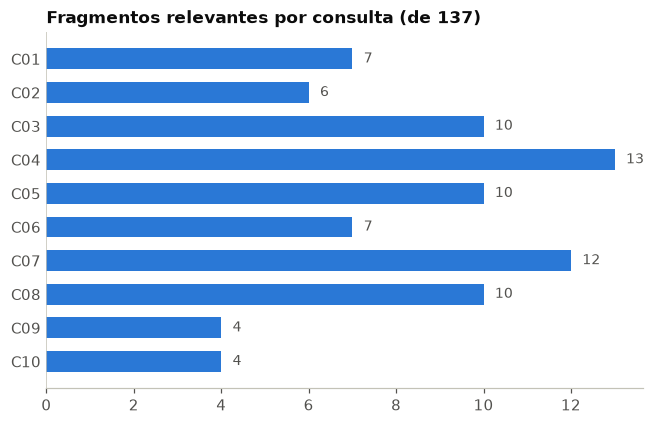

,consulta,fragmentos relevantes
0,C01,7
1,C02,6
2,C03,10
3,C04,13
4,C05,10
5,C06,7
6,C07,12
7,C08,10
8,C09,4
9,C10,4


In [3]:
relevancia_de = {}
for posicion in range(len(juicios)):
    fila = juicios.iloc[posicion]
    clave = (fila["id_consulta"], fila["id_fragmento"])
    relevancia_de[clave] = int(fila["relevancia"])


def relevancia_del_fragmento(id_consulta: str, id_fragmento: str) -> int:
    """Devuelve la relevancia juzgada de un fragmento para una consulta.

    Args:
        id_consulta: Identificador de la consulta, por ejemplo "C01".
        id_fragmento: Identificador del fragmento.

    Returns:
        2, 1 o 0 (los fragmentos sin juicio valen 0).
    """
    return relevancia_de.get((id_consulta, id_fragmento), 0)


conteo_por_consulta = []
for id_consulta in consultas["id"]:
    cantidad = 0
    for id_fragmento in cuentos["id"]:
        if relevancia_del_fragmento(id_consulta, id_fragmento) >= 1:
            cantidad += 1
    conteo_por_consulta.append(cantidad)

utils.dibujar_barras(
    list(consultas["id"]),
    conteo_por_consulta,
    titulo="Fragmentos relevantes por consulta (de 137)",
    formato="{:.0f}",
)
filas_de_conteo = []
for posicion in range(len(consultas)):
    filas_de_conteo.append({
        "consulta": consultas.iloc[posicion]["id"],
        "fragmentos relevantes": conteo_por_consulta[posicion],
    })
utils.tabla(filas_de_conteo)

> **Para mirar.**
>
> - Cada consulta tiene entre 4 y 13 fragmentos relevantes de 137 (C09 y C10 tienen 4; C04, 13). Los promedios entre consultas mezclan casos de dificultad distinta.
> - Los juicios los redactó una persona con ayuda de un modelo y 39 de 83 son discutibles: todo lo que sigue depende de ellos.

## 2. Un ranking, a mano

Buscar es ordenar. Con vectores normalizados, la similitud entre la consulta y todos los fragmentos se calcula de una vez con un producto de matrices; después ordenamos de mayor a menor. Eso es, por dentro, lo que hace `coleccion.query`. Lo hacemos así para ver cada paso y para poder aplicar muchas configuraciones rápido.

Armamos tres configuraciones del mismo corpus: **A**, `e5-small` con los prefijos; **B**, `e5-small` **sin** los prefijos; **C**, el modelo `MiniLM` de la unidad 009.

In [4]:
textos = list(cuentos["texto"])
ids_de_fragmentos = list(cuentos["id"])

MODELO_MINILM = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

configuraciones = {
    "A: e5-small con prefijos": utils.crear_embeddings(con_prefijos=True),
    "B: e5-small sin prefijos": utils.crear_embeddings(con_prefijos=False),
    "C: MiniLM (unidad 009)": HuggingFaceEmbeddings(
        model_name=MODELO_MINILM,
        encode_kwargs={"normalize_embeddings": True},
    ),
}

matriz_por_configuracion = {}
for nombre, modelo in configuraciones.items():
    matriz_por_configuracion[nombre] = np.array(
        modelo.embed_documents(textos)
    )

matriz_a = matriz_por_configuracion["A: e5-small con prefijos"]
print(f"Matriz de la configuración A: {matriz_a.shape}")

Matriz de la configuración A: (137, 384)


In [5]:
def ordenar_fragmentos(vector_de_consulta: list[float], matriz) -> list[int]:
    """Ordena las posiciones de los fragmentos de mas a menos cercanos.

    Args:
        vector_de_consulta: Vector de la consulta, normalizado.
        matriz: Un vector normalizado por fila, uno por fragmento.

    Returns:
        Posiciones de los fragmentos, del mas cercano al mas lejano.
    """
    similitudes = matriz @ np.array(vector_de_consulta)
    return list(np.argsort(-similitudes))


primera_consulta = consultas.iloc[0]
vector = configuraciones["A: e5-small con prefijos"].embed_query(
    primera_consulta["consulta"]
)
orden = ordenar_fragmentos(vector, matriz_a)

filas_del_ranking = []
for puesto in range(5):
    posicion = orden[puesto]
    filas_del_ranking.append({
        "puesto": puesto + 1,
        "título": cuentos.iloc[posicion]["titulo"],
        "relevancia juzgada": relevancia_del_fragmento(
            primera_consulta["id"], ids_de_fragmentos[posicion]
        ),
    })
print(primera_consulta["consulta"])
utils.tabla(filas_del_ranking)

Un animal desea ser otra cosa distinta de lo que es


,puesto,título,relevancia juzgada
0,1,La rana que quería ser una rana auténtica,2
1,2,La rana que quería ser una rana auténtica,2
2,3,Noctilucas,0
3,4,La rana que quería ser una rana auténtica,2
4,5,La cocinera,0


> **Para mirar.**
>
> - Los puestos 1, 2 y 4 son fragmentos de «La rana que quería ser una rana auténtica» (relevancia 2); «Noctilucas» y «La cocinera» no son relevantes.
> - Un ranking se resume mirando en qué puesto aparece el primer relevante (el 1) y cuántos de los tres primeros lo son (2 de 3). Eso es lo que miden las dos funciones que siguen.

### Microlaboratorio 1 — Dos medidas

**Tarea.** Escribir las dos medidas más usadas para evaluar un ranking.  
**Producto.** `precision_en_k` y `rango_reciproco`, comprobadas con listas inventadas.  
**Antes de empezar.** Secciones 1 y 2.

Una lista de relevancias es el juicio de cada resultado **en el orden del ranking**: `[2, 0, 1]` quiere decir que el primero es relevante, el segundo no y el tercero responde en parte. Un resultado cuenta como relevante si su valor es 1 o 2.

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) condición del `if` | verdadera cuando el resultado es relevante | `relevancia >= 1` |
| (2) retorno | la proporción de aciertos entre los `k` primeros | `aciertos / k` |
| (3) retorno | uno dividido la posición del primer relevante | `1 / posicion` |

**Comprobación.** `precision_en_k([2, 0, 1, 0], 3)` da dos tercios, `rango_reciproco([0, 0, 1])` da un tercio, y una lista sin relevantes da 0.

> **Ayuda 1.** `precision_en_k` cuenta cuántos de los `k` primeros pasan la condición y los divide por `k`.  
> **Ayuda 2.** En `rango_reciproco`, la posición empieza en 1: si el primer relevante es el tercero, la medida es 1/3.

In [6]:
def precision_en_k(relevancias: list[int], k: int) -> float:
    """Calcula que proporcion de los k primeros resultados es relevante.

    Args:
        relevancias: Relevancia de cada resultado, en el orden del ranking.
        k: Cuantos resultados se miran.

    Returns:
        Un numero entre 0 y 1.
    """
    aciertos = 0
    for relevancia in relevancias[:k]:
        if False:  # COMPLETAR (1)
            aciertos += 1
    return 0.0  # COMPLETAR (2)


def rango_reciproco(relevancias: list[int]) -> float:
    """Calcula 1 dividido la posicion del primer resultado relevante.

    Args:
        relevancias: Relevancia de cada resultado, en el orden del ranking.

    Returns:
        Un numero entre 0 y 1; 0 si ningun resultado es relevante.
    """
    posicion = 0
    for relevancia in relevancias:
        posicion += 1
        if relevancia >= 1:
            return 0.0  # COMPLETAR (3)
    return 0.0


utils.comprobar(
    abs(precision_en_k([2, 0, 1, 0], 3) - 2 / 3) < 1e-9,
    "revisa (1) y (2): [2, 0, 1, 0] con k=3 tiene que dar 2/3",
)
utils.comprobar(
    abs(rango_reciproco([0, 0, 1]) - 1 / 3) < 1e-9
    and rango_reciproco([0, 0, 0]) == 0.0,
    "revisa (3): [0, 0, 1] tiene que dar 1/3 y sin relevantes, 0",
)

Todavia no: revisa (1) y (2): [2, 0, 1, 0] con k=3 tiene que dar 2/3
Todavia no: revisa (3): [0, 0, 1] tiene que dar 1/3 y sin relevantes, 0


A partir de acá usamos `utils.precision_en_k` y `utils.rango_reciproco`, que hacen lo mismo que las tuyas, para que la comparación funcione aunque todavía no las hayas resuelto.

## 3. Tres configuraciones, diez consultas

Para cada configuración y cada consulta: calculamos el vector de la consulta (con su prefijo, si corresponde), ordenamos los 137 fragmentos, convertimos el ranking en la lista de relevancias juzgadas y aplicamos las dos medidas.

In [7]:
def evaluar_configuracion(nombre: str, k: int = 3) -> list[dict]:
    """Evalua una configuracion con todas las consultas.

    Args:
        nombre: Nombre de la configuracion, clave de configuraciones.
        k: Cuantos resultados se miran para la precision.

    Returns:
        Una fila por consulta, con precision@k y rango reciproco.
    """
    modelo = configuraciones[nombre]
    matriz = matriz_por_configuracion[nombre]
    filas = []
    for posicion_de_consulta in range(len(consultas)):
        consulta = consultas.iloc[posicion_de_consulta]
        vector = modelo.embed_query(consulta["consulta"])
        orden = ordenar_fragmentos(vector, matriz)
        relevancias = []
        for posicion in orden:
            relevancias.append(
                relevancia_del_fragmento(
                    consulta["id"], ids_de_fragmentos[posicion]
                )
            )
        filas.append({
            "consulta": consulta["id"],
            "precision": utils.precision_en_k(relevancias, k),
            "rango_reciproco": utils.rango_reciproco(relevancias),
        })
    return filas


resultados = {}
for nombre in configuraciones:
    resultados[nombre] = evaluar_configuracion(nombre)


def promedio(filas: list[dict], clave: str) -> float:
    """Calcula el promedio de una clave en una lista de filas.

    Args:
        filas: Lista de diccionarios.
        clave: Clave numerica a promediar.

    Returns:
        El promedio.
    """
    total = 0.0
    for fila in filas:
        total += fila[clave]
    return total / len(filas)


resumen = []
for nombre, filas in resultados.items():
    resumen.append({
        "configuración": nombre,
        "precisión@3": round(promedio(filas, "precision"), 3),
        "rango recíproco": round(promedio(filas, "rango_reciproco"), 3),
    })
utils.tabla(resumen)

,configuración,precisión@3,rango recíproco
0,A: e5-small con prefijos,0.567,0.875
1,B: e5-small sin prefijos,0.533,0.795
2,C: MiniLM (unidad 009),0.433,0.745


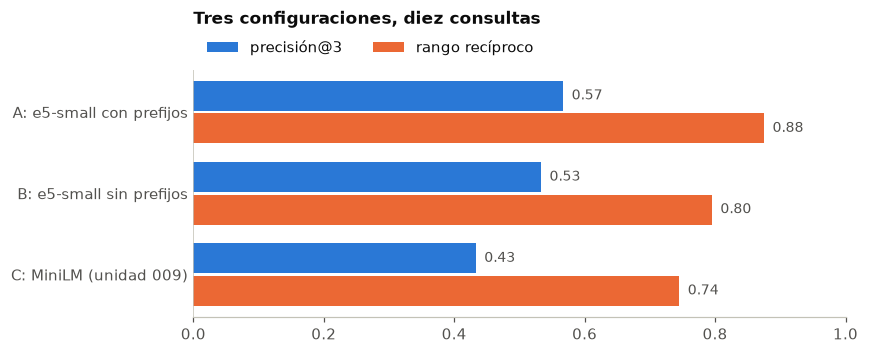

In [8]:
nombres = list(resultados.keys())
precisiones = []
rangos = []
for fila in resumen:
    precisiones.append(fila["precisión@3"])
    rangos.append(fila["rango recíproco"])

utils.dibujar_barras_agrupadas(
    nombres,
    {"precisión@3": precisiones, "rango recíproco": rangos},
    titulo="Tres configuraciones, diez consultas",
    maximo=1.0,
)

> **Para mirar.**
>
> - A (`e5-small` con prefijos) tiene la precisión@3 y el rango recíproco más altos: 0,567 y 0,875. B (sin prefijos): 0,533 y 0,795. C (`MiniLM`): 0,433 y 0,745.
> - El orden A, B, C se repite en las dos medidas. Pero son diez consultas con juicios discutibles: la sección siguiente mide cuánto se puede creer en esas diferencias.

## 4. ¿Cuánto cambia con otras diez consultas?

Una diferencia promedio entre dos configuraciones puede deberse a las diez consultas que elegimos. Para tantear cuánta incertidumbre hay, **remuestreamos**: armamos 2.000 grupos de diez consultas sacadas **con reposición** de las diez que tenemos, calculamos en cada grupo la diferencia de rango recíproco y miramos el rango que cubre el 90 % central. No es la verdad sobre todas las consultas posibles: es una idea de cuánto se movería el resultado.

In [9]:
def intervalo_de_la_diferencia(
    valores_a: list[float],
    valores_b: list[float],
    repeticiones: int = 2000,
    semilla: int = 42,
) -> tuple[float, float]:
    """Calcula el rango central de la diferencia promedio entre dos listas.

    Args:
        valores_a: Medida por consulta de la configuracion A.
        valores_b: Medida por consulta de la configuracion B.
        repeticiones: Cuantos grupos remuestreados se arman.
        semilla: Numero que fija el azar del remuestreo.

    Returns:
        Los percentiles 5 y 95 de la diferencia promedio.
    """
    generador = np.random.default_rng(semilla)
    cantidad = len(valores_a)
    diferencias = []
    for repeticion in range(repeticiones):
        elegidas = generador.integers(0, cantidad, size=cantidad)
        suma = 0.0
        for posicion in elegidas:
            suma += valores_a[posicion] - valores_b[posicion]
        diferencias.append(suma / cantidad)
    bajo, alto = np.percentile(diferencias, [5, 95])
    return float(bajo), float(alto)


def lista_de(filas: list[dict], clave: str) -> list[float]:
    """Extrae una clave de cada fila.

    Args:
        filas: Lista de diccionarios.
        clave: Clave a extraer.

    Returns:
        Los valores, en el mismo orden.
    """
    valores = []
    for fila in filas:
        valores.append(fila[clave])
    return valores


rr_a = lista_de(resultados["A: e5-small con prefijos"], "rango_reciproco")
rr_b = lista_de(resultados["B: e5-small sin prefijos"], "rango_reciproco")
rr_c = lista_de(resultados["C: MiniLM (unidad 009)"], "rango_reciproco")

comparaciones = {
    "A menos B (el prefijo)": rr_b,
    "A menos C (el modelo)": rr_c,
}
filas_de_intervalos = []
for etiqueta, otra in comparaciones.items():
    bajo, alto = intervalo_de_la_diferencia(rr_a, otra)
    diferencia_media = (sum(rr_a) - sum(otra)) / len(rr_a)
    filas_de_intervalos.append({
        "comparación": etiqueta,
        "diferencia observada": round(diferencia_media, 3),
        "90 % central": f"{bajo:.3f} a {alto:.3f}",
        "incluye el cero": bajo <= 0 <= alto,
    })
utils.tabla(filas_de_intervalos)

,comparación,diferencia observada,90 % central,incluye el cero
0,A menos B (el prefijo),0.08,0.000 a 0.230,True
1,A menos C (el modelo),0.13,-0.055 a 0.361,True


In [10]:
filas_por_consulta = []
for posicion in range(len(consultas)):
    filas_por_consulta.append({
        "consulta": consultas.iloc[posicion]["id"],
        "A": round(rr_a[posicion], 2),
        "B": round(rr_b[posicion], 2),
        "C": round(rr_c[posicion], 2),
    })
utils.tabla(filas_por_consulta)

,consulta,A,B,C
0,C01,1.00,1.00,1.00
1,C02,1.00,1.00,1.00
2,C03,1.00,1.00,1.00
3,C04,1.00,1.00,1.00
4,C05,0.50,0.50,1.00
5,C06,0.25,0.20,0.25
6,C07,1.00,1.00,1.00
7,C08,1.00,0.25,0.05
8,C09,1.00,1.00,1.00
9,C10,1.00,1.00,0.14


> **Para mirar.**
>
> - Las diferencias observadas de rango recíproco son 0,08 (A menos B) y 0,13 (A menos C). El 90 % central del remuestreo va de 0,000 a 0,230 y de -0,055 a 0,361: **los dos incluyen el cero** (el primero lo toca en el borde).
> - Las diferencias se concentran en pocas consultas: C08 (1,00 con prefijos, 0,25 sin prefijos y 0,05 con `MiniLM`) y C10 (`MiniLM` 0,14). En C05, `MiniLM` es mejor (1,00 contra 0,50).
> - Se puede decir que A es al menos tan buena como B y C en estos datos. No se puede decir que «el prefijo mejora» ni que `e5-small` supera a `MiniLM`: una consulta más o menos lo cambiaría.

## 5. Tamaño de fragmento y cantidad de resultados, en las políticas de Acme

Las decisiones de los cuadernos 01 y 03 (tamaño 500, `k=3`) no se midieron. Las medimos con nueve preguntas sobre el PDF de Acme. El criterio es más simple que el de los cuentos: un **acierto** es que un fragmento contenga una palabra esperada, y lo que registramos es **en qué puesto del ranking aparece el primero**. Cuatro preguntas son parafraseadas a propósito («partir mis vacaciones» en lugar de «fraccionamiento»).

In [11]:
preguntas_de_acme = [
    {
        "pregunta": (
            "¿Con cuánta anticipación debo pedir vacaciones y qué "
            "formulario uso?"
        ),
        "esperado": ["treinta", "rrhh-vac-01"],
    },
    {
        "pregunta": (
            "¿Hasta qué día del mes se piden los materiales dentro del "
            "presupuesto?"
        ),
        "esperado": ["dia diez"],
    },
    {
        "pregunta": (
            "¿Qué usos de inteligencia artificial no están "
            "permitidos?"
        ),
        "esperado": ["usos no permitidos"],
    },
    {
        "pregunta": (
            "¿Con cuánta anticipación se eleva una solicitud urgente de "
            "insumos?"
        ),
        "esperado": ["cuarenta y ocho"],
    },
    {
        "pregunta": (
            "¿Cuántos días de vacaciones corresponden con más de diez años "
            "de antigüedad?"
        ),
        "esperado": ["veinticinco"],
    },
    {
        "pregunta": "¿Puedo partir mis vacaciones en tramos cortos?",
        "esperado": ["fraccionamiento"],
    },
    {
        "pregunta": (
            "¿Cuánto tiempo tiene la gerencia para decidir un pedido "
            "extraordinario?"
        ),
        "esperado": ["veinticuatro horas"],
    },
    {
        "pregunta": "¿Qué pasa si divulgo las fórmulas de producción?",
        "esperado": ["falta grave"],
    },
    {
        "pregunta": "¿Quién se encarga del stock de tinturas y disolventes?",
        "esperado": ["sector de deposito"],
    },
]

paginas_de_acme = utils.cargar_pdf(
    utils.RUTA_DATOS / "politica_interna_tintas_acme.pdf",
    "politica_interna_tintas_acme.pdf",
)
modelo_de_acme = utils.crear_embeddings(con_prefijos=True)

In [12]:
def puesto_del_primer_acierto(
    fragmentos: list, orden: list[int], esperado: list[str]
) -> int:
    """Busca el puesto del primer fragmento con una palabra esperada.

    Args:
        fragmentos: Documentos indexados.
        orden: Posiciones de los fragmentos, del mas cercano al mas lejano.
        esperado: Palabras (normalizadas) de las que alcanza con una.

    Returns:
        El puesto (desde 1), o 0 si ningun fragmento la contiene.
    """
    puesto = 0
    for posicion in orden:
        puesto += 1
        texto = " ".join(fragmentos[posicion].page_content.split())
        texto = utils.normalizar(texto)
        for palabra in esperado:
            if palabra in texto:
                return puesto
    return 0


tamanos = (200, 500, 1000)
puestos_por_tamano = {}
cantidad_de_fragmentos = {}
for tamano in tamanos:
    divisor = RecursiveCharacterTextSplitter(
        chunk_size=tamano, chunk_overlap=tamano // 5
    )
    fragmentos = divisor.split_documents(paginas_de_acme)
    textos_de_fragmentos = []
    for fragmento in fragmentos:
        textos_de_fragmentos.append(fragmento.page_content)
    matriz = np.array(modelo_de_acme.embed_documents(textos_de_fragmentos))
    cantidad_de_fragmentos[tamano] = len(fragmentos)

    puestos = []
    for pregunta in preguntas_de_acme:
        vector = modelo_de_acme.embed_query(pregunta["pregunta"])
        orden = ordenar_fragmentos(vector, matriz)
        puestos.append(
            puesto_del_primer_acierto(fragmentos, orden, pregunta["esperado"])
        )
    puestos_por_tamano[tamano] = puestos

filas_por_pregunta = []
for posicion in range(len(preguntas_de_acme)):
    filas_por_pregunta.append({
        "pregunta": preguntas_de_acme[posicion]["pregunta"][:60],
        "puesto con 200": puestos_por_tamano[200][posicion],
        "puesto con 500": puestos_por_tamano[500][posicion],
        "puesto con 1000": puestos_por_tamano[1000][posicion],
    })
utils.tabla(filas_por_pregunta)

,pregunta,puesto con 200,puesto con 500,puesto con 1000
0,¿Con cuánta anticipación debo pedir vacaciones y qué formula,1,1,1
1,¿Hasta qué día del mes se piden los materiales dentro del pr,1,1,1
2,¿Qué usos de inteligencia artificial no están permitidos?,1,1,1
3,¿Con cuánta anticipación se eleva una solicitud urgente de i,1,1,1
4,¿Cuántos días de vacaciones corresponden con más de diez año,1,1,1
5,¿Puedo partir mis vacaciones en tramos cortos?,1,1,1
6,¿Cuánto tiempo tiene la gerencia para decidir un pedido extr,1,1,1
7,¿Qué pasa si divulgo las fórmulas de producción?,15,7,3
8,¿Quién se encarga del stock de tinturas y disolventes?,1,1,1


In [13]:
filas_de_resumen = []
for tamano in tamanos:
    puestos = puestos_por_tamano[tamano]
    fila = {"tamaño": tamano, "fragmentos": cantidad_de_fragmentos[tamano]}
    for k in (1, 3, 5):
        en_los_primeros = 0
        for puesto in puestos:
            if 0 < puesto <= k:
                en_los_primeros += 1
        fila[f"evidencia en los {k} primeros (de 9)"] = en_los_primeros
    filas_de_resumen.append(fila)
utils.tabla(filas_de_resumen)

,tamaño,fragmentos,evidencia en los 1 primeros (de 9),evidencia en los 3 primeros (de 9),evidencia en los 5 primeros (de 9)
0,200,31,8,8,8
1,500,13,8,8,8
2,1000,6,8,9,9


> **Para mirar.**
>
> - Con ocho de las nueve preguntas, la evidencia es el primer fragmento recuperado con cualquiera de los tres tamaños: esas preguntas no sirven para decidir.
> - La que distingue es la de las fórmulas de producción: la evidencia aparece en el puesto 15 con 200 caracteres, en el 7 con 500 y en el 3 con 1000. Una posible explicación, que no comprobamos, es que con fragmentos chicos la oración que importa queda separada de su contexto.
> - Con `k=3`, solo el tamaño 1000 trae la evidencia de las nueve preguntas. Una sola pregunta decide la diferencia: es una pista, no una conclusión, y un fragmento más largo le pasa más texto al generador.

### Microlaboratorio 2 — Elegir una configuración y decirlo con sus límites

**Tarea.** Fijar la configuración que usarías y justificarla con la evidencia de este cuaderno.  
**Producto.** `eleccion` y `mi_decision`.  
**Antes de empezar.** Secciones 3, 4 y 5.

| Paso | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `eleccion["prefijos"]` | si usarías o no los prefijos de `e5-small` | `True` o `False` |
| (2) `eleccion["k"]` | cuántos fragmentos le pasarías al generador | 1, 3 o 5, según la tabla de la sección 5 |
| (3) `eleccion["tamano"]` | el tamaño de fragmento | 200, 500 o 1000, según la tabla de la sección 5 |
| Paso 3 | tu decisión en `mi_decision` | al menos 40 palabras que citen **una cifra** y **un límite** (cuántas consultas, quién juzgó, el intervalo) |

> **Ayuda 1.** Mirá si el intervalo de la comparación con y sin prefijos incluye el cero: si lo incluye, ¿la evidencia alcanza para afirmar que el prefijo mejora? Y aun así, ¿hay una razón para usarlo?  
> **Ayuda 2.** Un `k` mayor trae más evidencia pero también más texto para el generador, que puede confundirse (cuaderno 03).

In [14]:
eleccion = {
    "modelo": "e5-small",
    "prefijos": False,  # COMPLETAR (1)
    "k": 0,  # COMPLETAR (2)
    "tamano": 0,  # COMPLETAR (3)
}

utils.comprobar(
    eleccion["prefijos"] is True,
    "revisa (1): la documentacion del modelo exige los prefijos",
)
utils.comprobar(
    eleccion["k"] in (1, 3, 5) and eleccion["tamano"] in (200, 500, 1000),
    "revisa (2) y (3): elegi valores de k y de tamano que se midieron",
)

mi_decision = ""
utils.comprobar(
    len(mi_decision.split()) >= 40,
    "escribi al menos 40 palabras en mi_decision",
)

Todavia no: revisa (1): la documentacion del modelo exige los prefijos
Todavia no: revisa (2) y (3): elegi valores de k y de tamano que se midieron
Todavia no: escribi al menos 40 palabras en mi_decision


## Qué te llevás

- Evaluar una búsqueda exige tres cosas escritas **antes**: consultas, criterio de relevancia y juicios. Con eso, **precisión@k** y **rango recíproco** convierten un ranking en un número comparable.
- Con diez consultas, las diferencias entre configuraciones suelen ser **del tamaño de la incertidumbre**: el remuestreo muestra un rango, no una verdad. Ningún cambio de configuración se justifica solo por «dicen que es mejor».
- Las decisiones de diseño de un RAG (modelo, prefijo, tamaño de fragmento, cantidad de resultados) se pueden **medir con pocos casos bien elegidos**, y la medición conviene repetirla cada vez que cambia alguna.

**Sigue:** la unidad 015, donde el modelo deja de seguir un recorrido fijo y decide qué herramienta usar, incluida la búsqueda que armamos acá.